In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

assert PROJECT_ROOT.exists(), "Project folder not found!"

GRADCAM_RESULTS_DIR = PROJECT_ROOT / "04_Results" / "GradCAM_Explainability"
GRADCAM_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive connected successfully!")
print("Project root:", PROJECT_ROOT)
print("Grad-CAM results folder:", GRADCAM_RESULTS_DIR)

Mounted at /content/drive
Google Drive connected successfully!
Project root: /content/drive/MyDrive/Insight_Hunters_Project
Grad-CAM results folder: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability


In [ ]:
import tensorflow as tf

# The custom preprocessing layer used during NIH training
@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        return (
            tf.reverse(inputs, axis=[-1])
            - tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)
        )

    def get_config(self):
        return super().get_config()


# Path to our final NIH-pretrained TB model
MODEL_PATH = (
    PROJECT_ROOT
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_to_TB"
    / "nih_tb_final_selected.keras"
)

assert MODEL_PATH.exists(), "Model checkpoint not found!"

# Loading the trained model without recompiling
gradcam_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

# Accessing the ResNet50 backbone
backbone = gradcam_model.get_layer("resnet50")

# Identifying the final convolutional feature layer
target_layer = backbone.get_layer("conv5_block3_out")

print("GRAD-CAM MODEL VERIFICATION")
print("=" * 50)

print("Model:", gradcam_model.name)
print("Total parameters:", gradcam_model.count_params())
print("Model output shape:", gradcam_model.output_shape)
print("Backbone:", backbone.name)
print("Target layer:", target_layer.name)
print("Target layer output shape:", target_layer.output.shape)

print("\nSUCCESS: NIH-pretrained ResNet50 loaded successfully!")

GRAD-CAM MODEL VERIFICATION
Model: NIH_Pretrained_ResNet50_TB
Total parameters: 23850113
Model output shape: (None, 1)
Backbone: resnet50
Target layer: conv5_block3_out
Target layer output shape: (None, 7, 7, 2048)

SUCCESS: NIH-pretrained ResNet50 loaded successfully!


In [ ]:
# Building a feature extractor from the ResNet50 backbone
feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        target_layer.output,
        backbone.output
    ]
)

# Verifying the feature extractor
print("GRAD-CAM FEATURE EXTRACTOR")
print("=" * 50)

print("Feature extractor:", feature_extractor.name)
print("Input shape:", feature_extractor.input_shape)

print("Convolutional feature shape:",
      feature_extractor.output_shape[0])

print("Backbone output shape:",
      feature_extractor.output_shape[1])

print("\nSUCCESS: Grad-CAM feature extractor created!")

GRAD-CAM FEATURE EXTRACTOR
Feature extractor: functional
Input shape: (None, 224, 224, 3)
Convolutional feature shape: (None, 7, 7, 2048)
Backbone output shape: (None, 7, 7, 2048)

SUCCESS: Grad-CAM feature extractor created!


In [ ]:
def generate_gradcam(image_batch, positive_class=True):

    image_batch = tf.convert_to_tensor(
        image_batch, dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        x = image_batch

        # Applying preprocessing, and skipping the InputLayer
        for layer in gradcam_model.layers[:backbone_index]:

            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        # Extracting the convolutional features
        conv_outputs, x = feature_extractor(
            x, training=False
        )

        tape.watch(conv_outputs)

        # Applying the trained classification head
        for layer in classification_layers:
            x = layer(x, training=False)

        # Selecting the class to explain
        score = x[:, 0] if positive_class else 1.0 - x[:, 0]

    # Calculating the gradients
    gradients = tape.gradient(score, conv_outputs)

    if gradients is None:
        raise RuntimeError(
            "Grad-CAM gradients could not be calculated."
        )

    # Calculating the channel importance
    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )

    # Generating a weighted heatmap
    heatmap = tf.reduce_sum(
        weights * conv_outputs, axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    # Normalising the heatmap
    heatmap = heatmap / (
        tf.reduce_max(
            heatmap, axis=(1, 2), keepdims=True
        ) + 1e-8
    )

    return heatmap.numpy()


print("Grad-CAM function defined!")

Grad-CAM function defined!


FIRST GRAD-CAM TEST IMAGE
Image: CHNCXR_0333_1.png
Actual class: TB Positive
Predicted TB probability: 0.9536
Predicted class: TB Positive
Image batch shape: (1, 224, 224, 3)


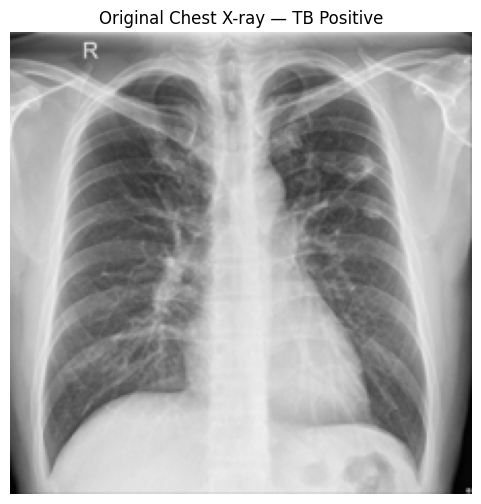

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Locating TB-positive test images
TEST_POSITIVE_DIR = (
    PROJECT_ROOT
    / "02_Data_Splits"
    / "test"
    / "tb_positive"
)

assert TEST_POSITIVE_DIR.exists(), "TB-positive test folder not found!"

# Finding the available chest X-rays
image_paths = sorted(
    [
        p for p in TEST_POSITIVE_DIR.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
)

assert len(image_paths) > 0, "No TB-positive test images found!"

# Selecting the first image
selected_image_path = image_paths[0]

# Loading the image using the same dimensions as training
image = Image.open(selected_image_path).convert("RGB")
image = image.resize((224, 224))

# Converting to the models input format
image_array = np.array(image, dtype=np.float32)

# Adding batch dimensions
image_batch = np.expand_dims(image_array, axis=0)

# Generating the models prediction
prediction = float(
    gradcam_model(image_batch, training=False).numpy()[0, 0]
)

print("FIRST GRAD-CAM TEST IMAGE")
print("=" * 50)

print("Image:", selected_image_path.name)
print("Actual class: TB Positive")
print(f"Predicted TB probability: {prediction:.4f}")
print("Predicted class:", "TB Positive" if prediction >= 0.5 else "TB Negative")
print("Image batch shape:", image_batch.shape)

# Displaying the original chest X-ray
plt.figure(figsize=(6, 6))
plt.imshow(image_array.astype(np.uint8))
plt.title("Original Chest X-ray — TB Positive")
plt.axis("off")
plt.show()

GRAD-CAM VERIFICATION
Heatmap shape: (1, 7, 7)
Minimum activation: 0.0
Maximum activation: 0.9999991


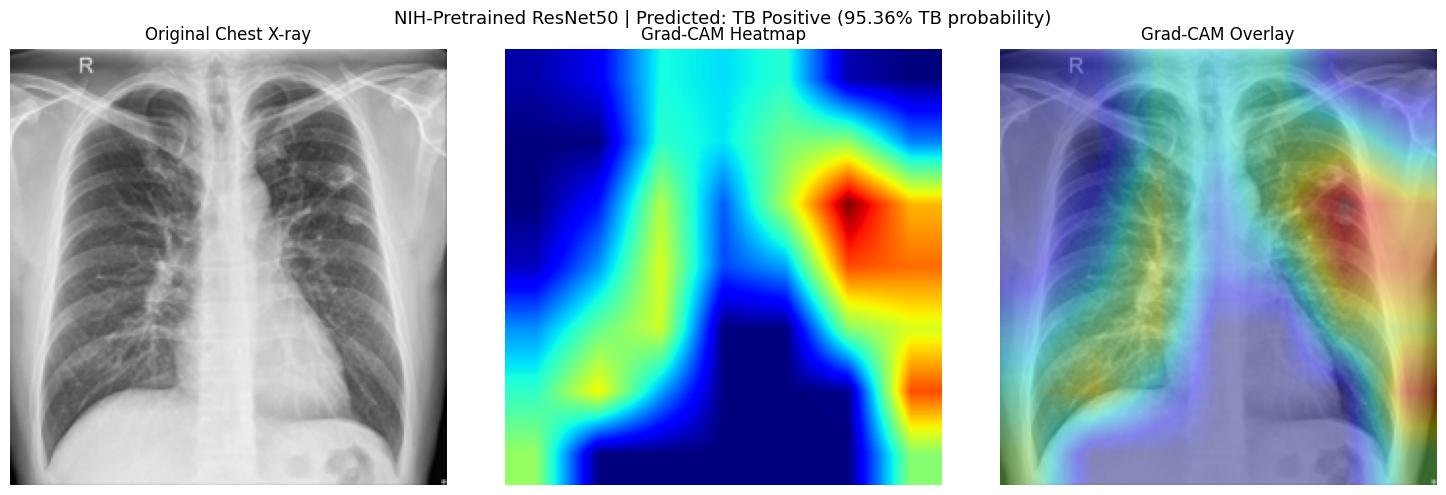


SUCCESS: First Grad-CAM visualisation generated!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Explaining the class predicted by our model
predicted_positive = prediction >= 0.5

# Generating the Grad-CAM heatmap
heatmap = generate_gradcam(
    image_batch,
    positive_class=predicted_positive
)

# Verifying the heatmap
assert heatmap.shape == (1, 7, 7), "Unexpected heatmap shape!"
assert np.all(np.isfinite(heatmap)), "Heatmap contains invalid values!"

print("GRAD-CAM VERIFICATION")
print("=" * 50)

print("Heatmap shape:", heatmap.shape)
print("Minimum activation:", heatmap.min())
print("Maximum activation:", heatmap.max())

# Resizing the heatmap to match original image
resized_heatmap = tf.image.resize(
    heatmap[0, :, :, np.newaxis],
    (224, 224),
    method="bilinear"
).numpy().squeeze()

# Creating the heatmap overlay
colormap = plt.get_cmap("jet")
colored_heatmap = colormap(resized_heatmap)[..., :3]

original_image = image_array / 255.0

overlay = (
    0.6 * original_image
    + 0.4 * colored_heatmap
)

overlay = np.clip(overlay, 0, 1)

# Displaying the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(resized_heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"NIH-Pretrained ResNet50 | "
    f"Predicted: {'TB Positive' if predicted_positive else 'TB Negative'} "
    f"({prediction:.2%} TB probability)",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("\nSUCCESS: First Grad-CAM visualisation generated!")

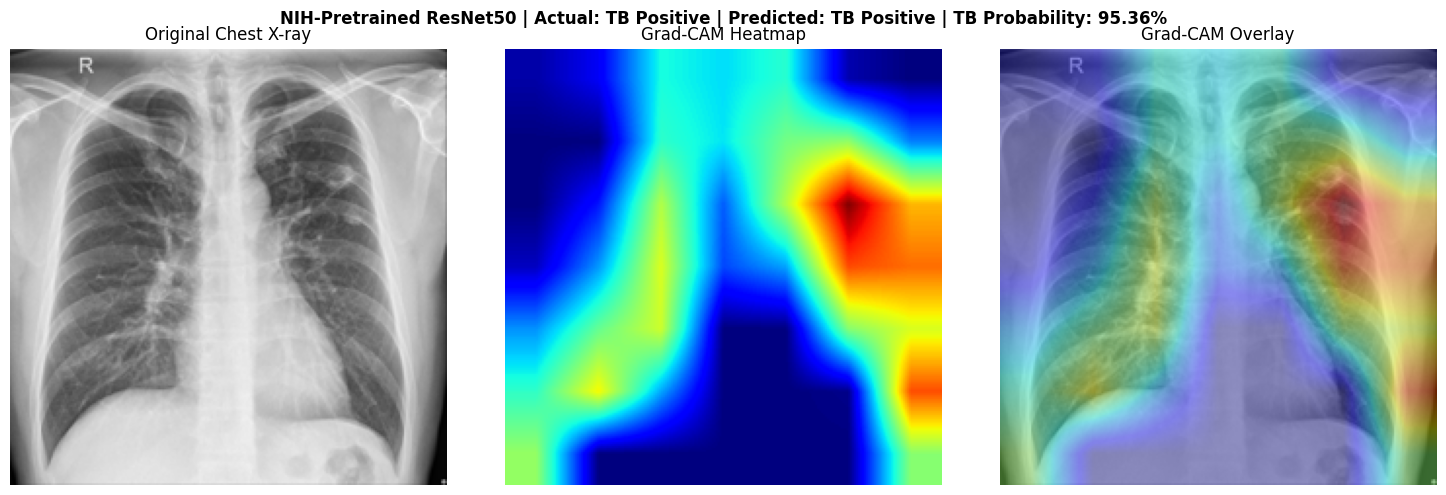

GRAD-CAM VISUALISATION SAVED
Image: CHNCXR_0333_1.png
Saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/NIH_ResNet50/CHNCXR_0333_1_gradcam.png

SUCCESS: First Grad-CAM result saved!


In [ ]:
# Creating a folder for the NIH-pretrained Grad-CAM results
NIH_GRADCAM_DIR = GRADCAM_RESULTS_DIR / "NIH_ResNet50"
NIH_GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

# Creating a descriptive filename
image_name = selected_image_path.stem

output_path = NIH_GRADCAM_DIR / f"{image_name}_gradcam.png"

# Creating a presentation-quality figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(resized_heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"NIH-Pretrained ResNet50 | "
    f"Actual: TB Positive | "
    f"Predicted: {'TB Positive' if predicted_positive else 'TB Negative'} "
    f"| TB Probability: {prediction:.2%}",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

# Saving the high-resolution image
plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("GRAD-CAM VISUALISATION SAVED")
print("=" * 50)
print("Image:", selected_image_path.name)
print("Saved to:", output_path)
print("\nSUCCESS: First Grad-CAM result saved!")

In [ ]:
import pandas as pd
import numpy as np
from PIL import Image

TEST_DIR = PROJECT_ROOT / "02_Data_Splits" / "test"

records = []

for class_name, actual_label in [
    ("tb_negative", 0),
    ("tb_positive", 1)
]:
    class_dir = TEST_DIR / class_name

    image_paths = sorted([
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ])

    for image_path in image_paths:
        image = Image.open(image_path).convert("RGB")
        image = image.resize((224, 224))

        image_array = np.asarray(image, dtype=np.float32)
        image_batch = np.expand_dims(image_array, axis=0)

        probability = float(
            gradcam_model(image_batch, training=False).numpy()[0, 0]
        )

        predicted_label = int(probability >= 0.5)

        if actual_label == 1 and predicted_label == 1:
            category = "TP"
        elif actual_label == 0 and predicted_label == 0:
            category = "TN"
        elif actual_label == 0 and predicted_label == 1:
            category = "FP"
        else:
            category = "FN"

        records.append({
            "Image": image_path.name,
            "Path": str(image_path),
            "Actual_Label": actual_label,
            "Predicted_Label": predicted_label,
            "TB_Probability": probability,
            "Category": category
        })

gradcam_predictions_df = pd.DataFrame(records)

print("GRAD-CAM PREDICTION CATEGORIES")
print("=" * 50)

print(
    gradcam_predictions_df["Category"]
    .value_counts()
    .reindex(["TP", "TN", "FP", "FN"], fill_value=0)
)

print("\nTotal images:", len(gradcam_predictions_df))

assert len(gradcam_predictions_df) == 120, (
    "Unexpected number of test images!"
)

# Saving the predictions for reproducibility
predictions_path = (
    GRADCAM_RESULTS_DIR / "gradcam_test_image_categories.csv"
)

gradcam_predictions_df.to_csv(predictions_path, index=False)

print("\nSaved to:", predictions_path)
print("\nSUCCESS: Test images categorised!")

GRAD-CAM PREDICTION CATEGORIES
Category
TP    51
TN    52
FP     9
FN     8
Name: count, dtype: int64

Total images: 120

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/gradcam_test_image_categories.csv

SUCCESS: Test images categorised!


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

TEST_DIR = PROJECT_ROOT / "02_Data_Splits" / "test"

# Recreating the original TensorFlow test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=["tb_negative", "tb_positive"],
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

# Collecting the actual labels
y_true_check = np.concatenate([
    labels.numpy().ravel()
    for _, labels in test_ds
]).astype(int)

# Generating the predictions
y_prob_check = gradcam_model.predict(test_ds, verbose=1).ravel()

y_pred_check = (y_prob_check >= 0.5).astype(int)

# Calculating the confusion matrix
cm_check = confusion_matrix(y_true_check, y_pred_check)

print("\nORIGINAL EVALUATION REPRODUCTION")
print("=" * 50)

print("Confusion matrix:")
print(cm_check)

print("\nAccuracy:", f"{accuracy_score(y_true_check, y_pred_check):.2%}")

print("\nExpected confusion matrix:")
print(np.array([[56, 5], [10, 49]]))

# Verifying the results
expected_cm = np.array([[56, 5], [10, 49]])

if np.array_equal(cm_check, expected_cm):
    print("\nSUCCESS: Original evaluation reproduced!")
else:
    print("\nWARNING: Results still differ. Further investigation needed.")

Found 120 files belonging to 2 classes.
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step

ORIGINAL EVALUATION REPRODUCTION
Confusion matrix:
[[56  5]
 [10 49]]

Accuracy: 87.50%

Expected confusion matrix:
[[56  5]
 [10 49]]

SUCCESS: Original evaluation reproduced!


In [ ]:
import pandas as pd
import numpy as np

# Retrieving the image paths in TensorFlow's evaluation order
test_image_paths = [
    str(path)
    for path in test_ds.file_paths
]

# Verifying the alignment
assert len(test_image_paths) == len(y_true_check) == len(y_prob_check)

# Categorising predictions
categories = []

for actual, predicted in zip(y_true_check, y_pred_check):

    if actual == 1 and predicted == 1:
        categories.append("TP")

    elif actual == 0 and predicted == 0:
        categories.append("TN")

    elif actual == 0 and predicted == 1:
        categories.append("FP")

    else:
        categories.append("FN")

# Creating verified prediction records
gradcam_predictions_df = pd.DataFrame({
    "Image": [Path(p).name for p in test_image_paths],
    "Path": test_image_paths,
    "Actual_Label": y_true_check,
    "Predicted_Label": y_pred_check,
    "TB_Probability": y_prob_check,
    "Category": categories
})

print("VERIFIED GRAD-CAM PREDICTION CATEGORIES")
print("=" * 50)

print(
    gradcam_predictions_df["Category"]
    .value_counts()
    .reindex(["TP", "TN", "FP", "FN"], fill_value=0)
)

# Verifying the against original evaluation
assert (
    gradcam_predictions_df["Category"]
    .value_counts()
    .reindex(["TP", "TN", "FP", "FN"], fill_value=0)
    .tolist()
    == [49, 56, 5, 10]
), "Prediction categories do not match original evaluation!"

# Saving the corrected records
verified_path = (
    GRADCAM_RESULTS_DIR
    / "gradcam_test_image_categories_verified.csv"
)

gradcam_predictions_df.to_csv(verified_path, index=False)

print("\nVerified predictions saved to:", verified_path)
print("\nSUCCESS: Grad-CAM image records verified!")

VERIFIED GRAD-CAM PREDICTION CATEGORIES
Category
TP    49
TN    56
FP     5
FN    10
Name: count, dtype: int64

Verified predictions saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/gradcam_test_image_categories_verified.csv

SUCCESS: Grad-CAM image records verified!


TP: CHNCXR_0333_1.png | TB Probability: 0.9357 | Heatmap Maximum: 1.0000
TN: CHNCXR_0019_0.png | TB Probability: 0.0582 | Heatmap Maximum: 1.0000
FP: CHNCXR_0082_0.png | TB Probability: 0.8870 | Heatmap Maximum: 1.0000
FN: CHNCXR_0364_1.png | TB Probability: 0.1768 | Heatmap Maximum: 1.0000


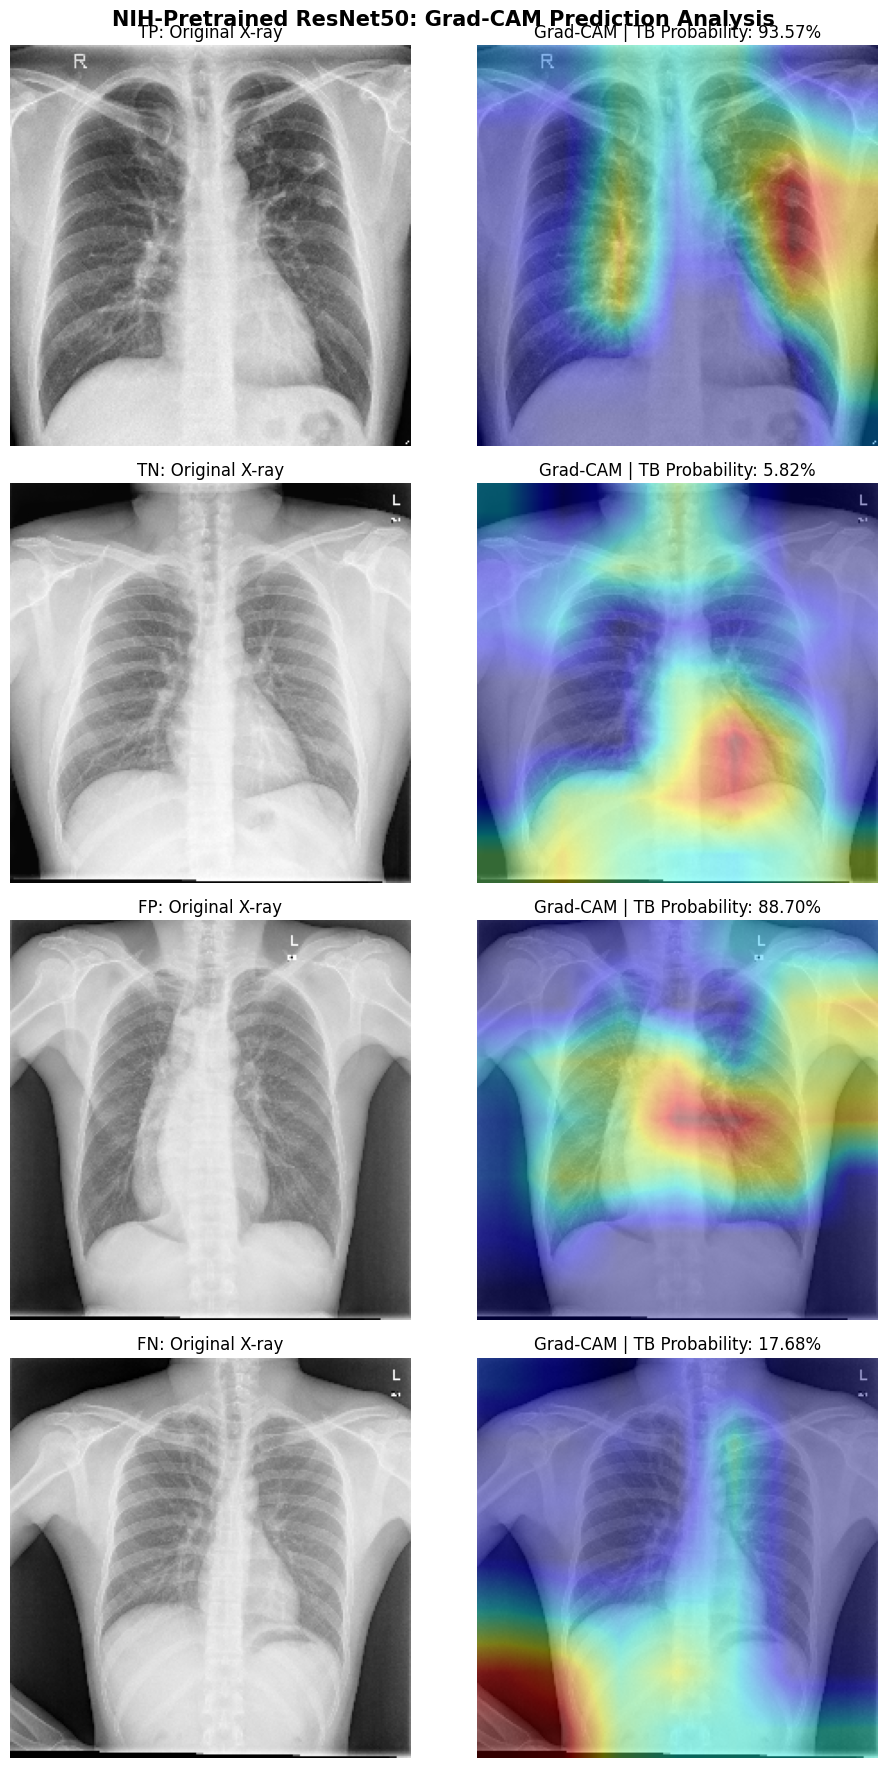

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

categories = ["TP", "TN", "FP", "FN"]

fig, axes = plt.subplots(4, 2, figsize=(10, 18))

for row, category in enumerate(categories):

    # Selecting the first image from this category
    record = gradcam_predictions_df[
        gradcam_predictions_df["Category"] == category
    ].iloc[0]

    # Loading the images using TensorFlow preprocessing
    image_bytes = tf.io.read_file(record["Path"])

    image_tensor = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image_tensor = tf.image.resize(
        image_tensor,
        (224, 224),
        method="bilinear"
    )

    image_batch = tf.expand_dims(image_tensor, axis=0)

    # Verifying that the prediction matches the saved record
    probability = float(
        gradcam_model(image_batch, training=False).numpy()[0, 0]
    )

    assert abs(probability - record["TB_Probability"]) < 1e-3, (
        f"Prediction mismatch for {record['Image']}"
    )

    # Explaining the predicted class
    predicted_positive = probability >= 0.5

    heatmap = generate_gradcam(
        image_batch,
        positive_class=predicted_positive
    )[0]

    # Resizing the heatmap
    resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Preparing an overlay
    original = image_tensor.numpy() / 255.0

    colored = plt.get_cmap("jet")(resized)[..., :3]

    overlay = np.clip(
        0.6 * original + 0.4 * colored,
        0,
        1
    )

    # Displaying the original image
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{category}: Original X-ray"
    )

    # Displaying the Grad-CAM overlay
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(
        f"Grad-CAM | TB Probability: {probability:.2%}"
    )

    for ax in axes[row]:
        ax.axis("off")

    print(
        f"{category}: {record['Image']} "
        f"| TB Probability: {probability:.4f} "
        f"| Heatmap Maximum: {heatmap.max():.4f}"
    )

plt.suptitle(
    "NIH-Pretrained ResNet50: Grad-CAM Prediction Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Saving the four-category Grad-CAM comparisons
comparison_path = (
    NIH_GRADCAM_DIR
    / "NIH_ResNet50_TP_TN_FP_FN_GradCAM_Comparison.png"
)

fig.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

print("GRAD-CAM COMPARISON SAVED")
print("=" * 50)
print("Saved to:", comparison_path)
print("\nSUCCESS: Four-category Grad-CAM comparison saved!")

GRAD-CAM COMPARISON SAVED
Saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/NIH_ResNet50/NIH_ResNet50_TP_TN_FP_FN_GradCAM_Comparison.png

SUCCESS: Four-category Grad-CAM comparison saved!


In [ ]:
from pathlib import Path

CHECKPOINT_DIR = PROJECT_ROOT / "03_Model_Checkpoints"

print("AVAILABLE RESNET50 CHECKPOINTS")
print("=" * 60)

resnet_checkpoints = sorted([
    path
    for path in CHECKPOINT_DIR.rglob("*.keras")
    if "resnet50" in str(path).lower()
])

for index, checkpoint in enumerate(resnet_checkpoints, start=1):
    print(f"{index}. {checkpoint.relative_to(PROJECT_ROOT)}")

print("\nTotal ResNet50 checkpoints found:", len(resnet_checkpoints))

AVAILABLE RESNET50 CHECKPOINTS
1. 03_Model_Checkpoints/ResNet50/ResNet50_stage1_best.keras
2. 03_Model_Checkpoints/ResNet50/ResNet50_stage2_best.keras
3. 03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/nih_resnet50_stage2_best.keras
4. 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_final_selected.keras
5. 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_save_test.keras
6. 03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
7. 03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_best.keras
8. 03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_final_selected.keras
9. 03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_best.keras

Total ResNet50 checkpoints found: 9


In [ ]:
import tensorflow as tf

# The original ResNet50 fine-tuned checkpoint
ORIGINAL_MODEL_PATH = (
    PROJECT_ROOT
    / "03_Model_Checkpoints"
    / "ResNet50"
    / "ResNet50_stage2_best.keras"
)

assert ORIGINAL_MODEL_PATH.exists(), "Original ResNet50 checkpoint not found!"

# Loading without modifying or recompiling the model
original_model = tf.keras.models.load_model(
    str(ORIGINAL_MODEL_PATH),
    compile=False
)

print("ORIGINAL RESNET50 MODEL VERIFICATION")
print("=" * 55)

print("Model:", original_model.name)
print("Total parameters:", original_model.count_params())
print("Input shape:", original_model.input_shape)
print("Output shape:", original_model.output_shape)

print("\nMODEL LAYERS")
print("=" * 55)

for index, layer in enumerate(original_model.layers):
    print(
        f"{index}. {layer.name} "
        f"| Type: {layer.__class__.__name__}"
    )

print("\nSUCCESS: Original ResNet50 checkpoint loaded!")

ORIGINAL RESNET50 MODEL VERIFICATION
Model: InsightHunters_ResNet50_TB
Total parameters: 23589761
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)

MODEL LAYERS
0. input_image | Type: InputLayer
1. shared_data_augmentation | Type: Sequential
2. resnet50 | Type: Functional
3. global_average_pooling | Type: GlobalAveragePooling2D
4. dropout | Type: Dropout
5. tb_prediction | Type: Dense

SUCCESS: Original ResNet50 checkpoint loaded!


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

# Using the verified TensorFlow test dataset from Cell 9
original_probabilities = original_model.predict(
    test_ds,
    verbose=1
).ravel()

original_predictions = (
    original_probabilities >= 0.5
).astype(int)

original_cm = confusion_matrix(
    y_true_check,
    original_predictions
)

original_accuracy = accuracy_score(
    y_true_check,
    original_predictions
)

print("\nORIGINAL RESNET50 EVALUATION")
print("=" * 50)

print("Confusion matrix:")
print(original_cm)

print(f"\nAccuracy: {original_accuracy:.2%}")

print("\nExpected confusion matrix:")
print(np.array([
    [58, 3],
    [12, 47]
]))

expected_original_cm = np.array([
    [58, 3],
    [12, 47]
])

if np.array_equal(original_cm, expected_original_cm):
    print("\n Original ResNet50 results reproduced!")
else:
    print("\nWARNING: Results differ from original evaluation.")
    print("We need to investigate preprocessing or checkpoint selection.")

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 840ms/step

ORIGINAL RESNET50 EVALUATION
Confusion matrix:
[[58  3]
 [12 47]]

Accuracy: 87.50%

Expected confusion matrix:
[[58  3]
 [12 47]]

 Original ResNet50 results reproduced!


In [ ]:
# Accessing the original ResNet50 backbone
original_backbone = original_model.get_layer("resnet50")

# Identifying the final convolutional feature layer
original_target_layer = original_backbone.get_layer(
    "conv5_block3_out"
)

# Building a feature extractor
original_feature_extractor = tf.keras.Model(
    inputs=original_backbone.input,
    outputs=[
        original_target_layer.output,
        original_backbone.output
    ]
)

# Identifying the classification head layers
original_backbone_index = original_model.layers.index(
    original_backbone
)

original_classification_layers = original_model.layers[
    original_backbone_index + 1:
]

print("ORIGINAL RESNET50 GRAD-CAM SETUP")
print("=" * 55)

print("Backbone:", original_backbone.name)
print("Target layer:", original_target_layer.name)

print(
    "Convolutional feature shape:",
    original_feature_extractor.output_shape[0]
)

print("\nClassification head layers:")

for layer in original_classification_layers:
    print(" -", layer.name)

print("\n The original ResNet50 feature extractor is ready!")

ORIGINAL RESNET50 GRAD-CAM SETUP
Backbone: resnet50
Target layer: conv5_block3_out
Convolutional feature shape: (None, 7, 7, 2048)

Classification head layers:
 - global_average_pooling
 - dropout
 - tb_prediction

 The original ResNet50 feature extractor is ready!


In [ ]:
def generate_original_gradcam(image_batch, positive_class=True):

    image_batch = tf.convert_to_tensor(
        image_batch, dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        x = image_batch

        # Applying preprocessing and augmentation in inference mode
        for layer in original_model.layers[:original_backbone_index]:

            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        # Extracting convolutional features
        conv_outputs, x = original_feature_extractor(
            x, training=False
        )

        tape.watch(conv_outputs)

        # Applying the original classification head
        for layer in original_classification_layers:
            x = layer(x, training=False)

        # Selecting the class to explain
        score = x[:, 0] if positive_class else 1.0 - x[:, 0]

    # Calculating gradients
    gradients = tape.gradient(score, conv_outputs)

    if gradients is None:
        raise RuntimeError(
            "Original ResNet50 Grad-CAM gradients could not be calculated."
        )

    # Calculating channel importance
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
        keepdims=True
    )

    # Generating a weighted heatmap
    heatmap = tf.reduce_sum(
        weights * conv_outputs,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    # Normalising the heatmap
    heatmap = heatmap / (
        tf.reduce_max(
            heatmap,
            axis=(1, 2),
            keepdims=True
        ) + 1e-8
    )

    return heatmap.numpy()


print("The original ResNet50 Grad-CAM function is defined!")

The original ResNet50 Grad-CAM function is defined!


In [ ]:
import numpy as np
import tensorflow as tf

# Selecting the first verified true-positive image
test_record = gradcam_predictions_df[
    gradcam_predictions_df["Category"] == "TP"
].iloc[0]

# Loading the image using TensorFlow preprocessing
image_bytes = tf.io.read_file(test_record["Path"])

test_image = tf.io.decode_image(
    image_bytes,
    channels=3,
    expand_animations=False
)

test_image = tf.image.resize(
    test_image,
    (224, 224),
    method="bilinear"
)

test_batch = tf.expand_dims(test_image, axis=0)

# Generating predictions from both models
original_prob = float(
    original_model(test_batch, training=False).numpy()[0, 0]
)

nih_prob = float(
    gradcam_model(test_batch, training=False).numpy()[0, 0]
)

# Generating the original ResNet50 Grad-CAM
original_heatmap = generate_original_gradcam(
    test_batch,
    positive_class=original_prob >= 0.5
)

# Verifying the heatmap
assert original_heatmap.shape == (1, 7, 7)
assert np.all(np.isfinite(original_heatmap))

print("ORIGINAL RESNET50 GRAD-CAM VERIFICATION")
print("=" * 55)

print("Image:", test_record["Image"])
print(f"Original ResNet50 TB probability: {original_prob:.2%}")
print(f"NIH-pretrained ResNet50 TB probability: {nih_prob:.2%}")

print("\nHeatmap shape:", original_heatmap.shape)
print("Minimum activation:", original_heatmap.min())
print("Maximum activation:", original_heatmap.max())

if original_heatmap.max() > 0:
    print("\n The original ResNet50 Grad-CAM is generated!")
else:
    print("\nWARNING: Heatmap contains no positive activations.")

ORIGINAL RESNET50 GRAD-CAM VERIFICATION
Image: CHNCXR_0333_1.png
Original ResNet50 TB probability: 94.85%
NIH-pretrained ResNet50 TB probability: 93.57%

Heatmap shape: (1, 7, 7)
Minimum activation: 0.0
Maximum activation: 0.99999964

 The original ResNet50 Grad-CAM is generated!


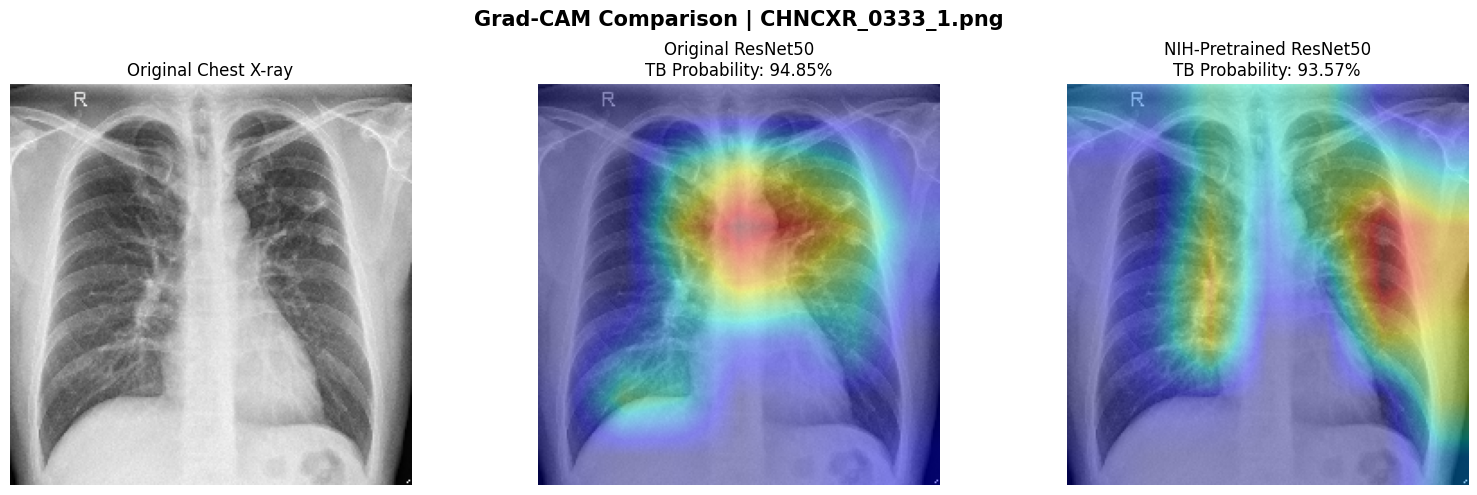

GRAD-CAM MODEL COMPARISON
Image: CHNCXR_0333_1.png
Original ResNet50: 94.85%
NIH-pretrained ResNet50: 93.57%

 Side-by-side Grad-CAM comparison has been generated!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Generating the NIH-pretrained Grad-CAM for the same X-ray
nih_heatmap = generate_gradcam(
    test_batch,
    positive_class=nih_prob >= 0.5
)[0]

# Retrieving the original ResNet50 heatmap
original_map = original_heatmap[0]

# Resizing both heatmaps
original_resized = tf.image.resize(
    original_map[..., np.newaxis],
    (224, 224),
    method="bilinear"
).numpy().squeeze()

nih_resized = tf.image.resize(
    nih_heatmap[..., np.newaxis],
    (224, 224),
    method="bilinear"
).numpy().squeeze()

# Preparing the original image
original_xray = np.clip(
    test_image.numpy() / 255.0,
    0,
    1
)

# Applying the identical colour mapping
colormap = plt.get_cmap("jet")

original_colored = colormap(original_resized)[..., :3]
nih_colored = colormap(nih_resized)[..., :3]

# Creating overlays
original_overlay = np.clip(
    0.6 * original_xray + 0.4 * original_colored,
    0,
    1
)

nih_overlay = np.clip(
    0.6 * original_xray + 0.4 * nih_colored,
    0,
    1
)

# Displaying the comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_xray)
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(original_overlay)
axes[1].set_title(
    f"Original ResNet50\nTB Probability: {original_prob:.2%}"
)

axes[2].imshow(nih_overlay)
axes[2].set_title(
    f"NIH-Pretrained ResNet50\nTB Probability: {nih_prob:.2%}"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Grad-CAM Comparison | {test_record['Image']}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("GRAD-CAM MODEL COMPARISON")
print("=" * 50)
print("Image:", test_record["Image"])
print(f"Original ResNet50: {original_prob:.2%}")
print(f"NIH-pretrained ResNet50: {nih_prob:.2%}")
print("\n Side-by-side Grad-CAM comparison has been generated!")

In [ ]:
# Creating a folder for model-to-model comparisons
MODEL_COMPARISON_DIR = (
    GRADCAM_RESULTS_DIR / "ResNet50_Model_Comparisons"
)

MODEL_COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Saving the comparison using the image filename
comparison_path = (
    MODEL_COMPARISON_DIR
    / f"{Path(test_record['Image']).stem}_Model_Comparison.png"
)

fig.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

print("GRAD-CAM MODEL COMPARISON SAVED")
print("=" * 55)

print("Image:", test_record["Image"])
print("Saved to:", comparison_path)

print("\nModel comparison saved!")

GRAD-CAM MODEL COMPARISON SAVED
Image: CHNCXR_0333_1.png
Saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/ResNet50_Model_Comparisons/CHNCXR_0333_1_Model_Comparison.png

Model comparison saved!


In [ ]:
import pandas as pd
import numpy as np

# Using the verified predictions from both models
comparison_records = gradcam_predictions_df.copy()

comparison_records["Original_Probability"] = original_probabilities
comparison_records["Original_Prediction"] = original_predictions

comparison_records["NIH_Probability"] = y_prob_check
comparison_records["NIH_Prediction"] = y_pred_check

# Determining whether each model was correct
original_correct = (
    comparison_records["Original_Prediction"]
    == comparison_records["Actual_Label"]
)

nih_correct = (
    comparison_records["NIH_Prediction"]
    == comparison_records["Actual_Label"]
)

# Categorising both agreement and disagreement
conditions = [
    original_correct & nih_correct,
    ~original_correct & ~nih_correct,
    original_correct & ~nih_correct,
    ~original_correct & nih_correct
]

categories = [
    "Both Correct",
    "Both Wrong",
    "Original Only Correct",
    "NIH Only Correct"
]

comparison_records["Comparison_Category"] = np.select(
    conditions,
    categories,
    default="Uncategorised"
)

# Displaying the category counts
print("RESNET50 MODEL AGREEMENT ANALYSIS")
print("=" * 55)

category_counts = (
    comparison_records["Comparison_Category"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

print(category_counts)

print("\nTotal images:", len(comparison_records))

# Verifying whether all the images are categorised
assert len(comparison_records) == 120
assert category_counts.sum() == 120

# Saving the comparison records
agreement_path = (
    GRADCAM_RESULTS_DIR
    / "resnet50_model_agreement_analysis.csv"
)

comparison_records.to_csv(
    agreement_path,
    index=False
)

print("\nSaved to:", agreement_path)
print("\nModel agreement analysis complete!")

RESNET50 MODEL AGREEMENT ANALYSIS
Comparison_Category
Both Correct             102
Both Wrong                12
Original Only Correct      3
NIH Only Correct           3
Name: count, dtype: int64

Total images: 120

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/GradCAM_Explainability/resnet50_model_agreement_analysis.csv

Model agreement analysis complete!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

comparison_categories = [
    "Both Correct",
    "Both Wrong",
    "Original Only Correct",
    "NIH Only Correct"
]

fig, axes = plt.subplots(4, 3, figsize=(15, 19))

for row, category in enumerate(comparison_categories):

    # Selecting one image from each agreement category
    record = comparison_records[
        comparison_records["Comparison_Category"] == category
    ].iloc[0]

    # Loading using TensorFlow preprocessing
    image_bytes = tf.io.read_file(record["Path"])

    image_tensor = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image_tensor = tf.image.resize(
        image_tensor,
        (224, 224),
        method="bilinear"
    )

    image_batch = tf.expand_dims(image_tensor, axis=0)

    # Generating predictions
    original_prob = float(
        original_model(image_batch, training=False).numpy()[0, 0]
    )

    nih_prob = float(
        gradcam_model(image_batch, training=False).numpy()[0, 0]
    )

    # Verifying whether predictions remain consistent with the saved evaluation
original_saved_class = int(record["Original_Prediction"])
nih_saved_class = int(record["NIH_Prediction"])

assert int(original_prob >= 0.5) == original_saved_class, (
    f"Original ResNet50 prediction changed for {record['Image']}"
)

assert int(nih_prob >= 0.5) == nih_saved_class, (
    f"NIH ResNet50 prediction changed for {record['Image']}"
)

print(
    f"Verified predictions for {record['Image']}"
)

    # Generating the Grad-CAM heatmaps
  original_heatmap = generate_original_gradcam(
        image_batch,
        positive_class=original_prob >= 0.5
    )[0]

    nih_heatmap = generate_gradcam(
        image_batch,
        positive_class=nih_prob >= 0.5
    )[0]

    # Resizing the heatmaps
    original_resized = tf.image.resize(
        original_heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    nih_resized = tf.image.resize(
        nih_heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Preparing the overlays
    original_xray = np.clip(
        image_tensor.numpy() / 255.0,
        0,
        1
    )

    colormap = plt.get_cmap("jet")

    original_overlay = np.clip(
        0.6 * original_xray
        + 0.4 * colormap(original_resized)[..., :3],
        0,
        1
    )

    nih_overlay = np.clip(
        0.6 * original_xray
        + 0.4 * colormap(nih_resized)[..., :3],
        0,
        1
    )

    # Displaying the original X-ray
    axes[row, 0].imshow(original_xray)
    axes[row, 0].set_title(
        f"{category}\n{record['Image']}"
    )

    # Displaying the original model overlay
    axes[row, 1].imshow(original_overlay)
    axes[row, 1].set_title(
        f"Original ResNet50\nTB: {original_prob:.2%}"
    )

    # Displaying the NIH model overlay
    axes[row, 2].imshow(nih_overlay)
    axes[row, 2].set_title(
        f"NIH-Pretrained ResNet50\nTB: {nih_prob:.2%}"
    )

    for ax in axes[row]:
        ax.axis("off")

    print(
        f"{category}: {record['Image']} | "
        f"Original: {original_prob:.2%} | "
        f"NIH: {nih_prob:.2%}"
    )

plt.suptitle(
    "Grad-CAM Comparison: ResNet50 Model Agreements and Disagreements",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Saving before displaying
output_path = (
    MODEL_COMPARISON_DIR
    / "ResNet50_GradCAM_Agreement_Disagreement_Comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:", output_path)
print("\nFinal Grad-CAM comparison generated!")

Output hidden; open in https://colab.research.google.com to view.

**Grad-CAM Explainability Analysis:** Findings and Conclusion

**1.Overview**

Whilst the evaluation of deep learning models provides valuable insight into their ability to accurately classify chest X-ray images, it does not necessarily explain how these predictions are made. This creates the need to further investigate the decision-making processes of the models, particularly when considering their potential application within a medical environment.

To address this, Gradient-weighted Class Activation Mapping (Grad-CAM) was implemented as an explainability technique for both the original ImageNet-pretrained ResNet50 and the NIH-pretrained ResNet50 models.

The primary purpose of this analysis was to gain a better understanding of the regions within chest X-ray images that influence the models' predictions, whilst also exploring whether differences could be observed between the two models.

Through the use of Grad-CAM, heatmaps were generated from the final convolutional feature layer (conv5_block3_out) of each ResNet50 backbone, allowing the areas contributing towards individual classification decisions to be visualised.


**2.Model Verification**

Before proceeding with the explainability analysis, it was important to ensure that both models were functioning as expected and that the correct trained checkpoints were being used.

To establish this, the original ResNet50 and NIH-pretrained ResNet50 models were evaluated against the same held-out test dataset consisting of 120 chest X-ray images.

The original ResNet50 achieved an accuracy of 87.50%, correctly identifying 47 TB-positive cases and 58 TB-negative cases. Similarly, the NIH-pretrained ResNet50 achieved an accuracy of 87.50%, correctly identifying 49 TB-positive cases and 56 TB-negative cases.

These results were consistent with the previously recorded evaluations, providing reassurance that the models had been loaded correctly and that the explainability analysis could proceed using their established performance results.

Although both models achieved the same overall accuracy, the differences in their ability to identify TB-positive and TB-negative cases presented an interesting opportunity to further explore their classification behaviour.


**3.Grad-CAM Visualisation Findings**

Following the successful verification of both models, Grad-CAM was implemented to generate visual representations of the regions contributing towards their predictions.

The analysis considered four classification outcomes, namely true positives, true negatives, false positives and false negatives. Including both correct and incorrect predictions was particularly important, as understanding the circumstances under which a model makes mistakes can be just as valuable as understanding its successful classifications.

Upon examining the generated heatmaps, differences could be observed in the regions highlighted across the selected chest X-ray images.

In some instances, the strongest activations appeared within the lung regions, whilst in others, the highlighted areas extended towards the boundaries of the images or regions outside the lungs.

These observations raise important questions regarding the visual features that the models may be relying on when making their predictions.

Although the highlighted regions provide some insight into the models' classification behaviour, it is important to acknowledge that Grad-CAM does not directly identify tuberculosis abnormalities. Rather, it highlights areas that contribute towards a particular prediction.

Therefore, the presence of strong activation within a specific region should not automatically be interpreted as evidence of tuberculosis or any other medical abnormality.

Nevertheless, the visualisations provided an additional perspective that could not have been obtained through conventional performance metrics alone.


**4.Model Agreement and Disagreement**

To further understand the relationship between the two models, a comparative analysis was conducted using their predictions across all 120 test images.

The purpose of this comparison was to determine whether the models were making similar classification decisions or whether differences existed despite their identical overall accuracy.

The following results were obtained:

Classification Outcome	Number of Images
Both models correct	102
Both models incorrect	12
Original ResNet50 correct only	3
NIH-pretrained ResNet50 correct only	3
Total	120

The findings revealed that both models agreed on 114 of the 120 images, representing an agreement of 95%.

However, six images produced different classification outcomes. Of these, three were correctly classified by the original ResNet50 but incorrectly classified by the NIH-pretrained model, whilst the remaining three were correctly classified by the NIH-pretrained model but incorrectly classified by the original ResNet50.

This was a particularly interesting finding, as it demonstrated that achieving the same overall accuracy does not necessarily mean that two models are making identical predictions.

Furthermore, the results highlighted the importance of looking beyond accuracy when evaluating deep learning models, especially within medical image classification, where the consequences of false-positive and false-negative predictions may differ.


**5.Comparative Grad-CAM Analysis**

Having established where the two models agreed and disagreed, a further comparison was conducted using Grad-CAM visualisations generated from the same chest X-ray images.

The analysis considered examples where both models were correct, both were incorrect, and instances where only one of the models produced the correct classification.

By examining the heatmaps side by side, it became possible to observe differences in the regions that contributed towards the models' predictions.

Interestingly, even in cases where both models correctly classified the same image, their heatmaps did not always highlight the same areas.

Similarly, differences were observed in examples where one model produced the correct prediction whilst the other did not.

These findings suggest that although the models may arrive at similar classification outcomes, the visual features influencing their predictions are not necessarily identical.

Considering that one model underwent ImageNet pretraining whilst the other received additional domain-specific pretraining using the NIH ChestX-ray14 dataset, these differences provide an interesting area for further investigation.

However, it would be inaccurate to conclude that NIH pretraining was solely responsible for the differences observed, as other aspects of the models' training procedures and architectures may also have contributed.

Furthermore, differences in highlighted regions do not necessarily indicate that one model has developed a better understanding of tuberculosis-related abnormalities.

Rather, the comparisons provide an opportunity to explore how different training approaches may influence the visual representations learned by deep learning models.


**6.Limitations**

Whilst Grad-CAM proved useful in providing a visual perspective of the models' predictions, several limitations must be acknowledged when interpreting the findings.

Firstly, Grad-CAM does not provide a complete explanation of how a deep learning model arrives at its predictions. Instead, it offers an approximate representation of the regions that contribute towards a particular classification decision.

As a result, the generated heatmaps should be viewed as supporting visualisations rather than definitive explanations of the models' reasoning.

Another important limitation is the absence of expert-annotated tuberculosis lesion locations within the explainability analysis. Without these annotations or an assessment conducted by qualified medical professionals, it is not possible to determine whether the highlighted regions correspond to clinically significant abnormalities.

Additionally, the heatmaps were generated from convolutional feature maps measuring only 7 × 7 pixels. Although these were resized to match the dimensions of the original chest X-ray images, doing so does not increase the actual spatial detail contained within the heatmaps.

The relatively small test dataset must also be considered. Whilst all 120 images were included in the prediction agreement analysis, the Grad-CAM visualisations examined in detail represented selected examples rather than a comprehensive visual assessment of every image.

Consequently, the observations made from these examples cannot necessarily be generalised across the entire dataset.

Lastly, differences between the models cannot be attributed exclusively to NIH pretraining, as their training procedures and classification architectures were not entirely identical.

These limitations reinforce the need for caution when interpreting explainability results, particularly within medical applications where incorrect assumptions could have serious implications.


**7.Conclusion**

The implementation of Grad-CAM served as an important extension to the evaluation of the ResNet50 models developed throughout this project.

Whilst the performance metrics obtained during model evaluation provided a quantitative understanding of their classification capabilities, the introduction of Grad-CAM allowed the analysis to extend beyond numerical results and explore the regions influencing individual predictions.

Through this process, it became evident that although the original ResNet50 and NIH-pretrained ResNet50 achieved identical overall accuracy, differences existed in both their classification outcomes and the spatial activation patterns observed within selected chest X-ray images.

This further emphasised the importance of considering multiple aspects of model performance rather than relying solely on accuracy as an indication of effectiveness.

The analysis also highlighted the value of investigating incorrect predictions, as these provide an opportunity to better understand the limitations of the models and identify areas that may require further attention.

Although the generated heatmaps cannot independently confirm whether the models are identifying clinically relevant tuberculosis abnormalities, they provide a useful foundation for exploring the explainability of deep learning systems within medical image classification.

Ultimately, the Grad-CAM analysis contributed towards the broader objectives of the Insight Hunters project by introducing an additional level of understanding into the behaviour of the developed models.

It is therefore evident that achieving strong classification performance is only one aspect of developing a reliable deep learning system. Understanding the factors that influence its predictions, acknowledging its limitations and recognising the importance of further clinical validation are equally important considerations, particularly when the intended application involves medical diagnosis.